# 04 Modeling (BUSA 310 Project 1)

**Input:** `data/processed/philly_sf_sales_clean.csv`

**This notebook reproduces the model currently on the website** (Random Forest, price, trained 2026-10-13, before the neighborhood variables were added).
**Group decisions (2026-10-12):**
- Drop all bundled sales (several parcels sold at one total price); keep vacant lots.
- Inputs: living area, bedrooms, bathrooms, ZIP, year built, interior and exterior condition, stories, garage spaces, central air, quality grade, sale year.
  `market_value` excluded (city's 2026 estimate, made after many of these sales: leakage).
- Target: compare price in dollars and log(price).
- Models: Linear Regression, Ridge, Random Forest, Gradient Boosting, plus a median baseline.
- Split: random 80/20, `random_state=42`.

**How the comparison stays fair:** every model sees the same training rows and is scored on the same test rows, in dollars.
Missing values are filled and categories encoded *inside* each model pipeline, so they are learned from training data only.
Model comparison uses 5-fold cross-validation on the training set; the test set is scored once at the end.

The numbers are printed; choosing the final model and interpreting the results is the group's job.

AI use note: modeling code drafted with Claude (Claude Code) from the group's stated choices; see AI Use Log.

## 0. Setup and load

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import sklearn
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

SEED = 42
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
CLEAN_PATH = "data/processed/philly_sf_sales_clean.csv"
CLEAN_URL = "https://raw.githubusercontent.com/HyeseongO/philly-home-price-predictor/main/data/philly_sf_sales_clean.csv"
source = CLEAN_PATH if os.path.exists(CLEAN_PATH) else CLEAN_URL  
print("loading data from:", source)

df = pd.read_csv(source, low_memory=False,
                 dtype={"zip_code": str, "parcel_number": str, "census_tract": str},
                 parse_dates=["sale_date"])
print("loaded:", df.shape)

pandas 3.0.5 | scikit-learn 1.9.1
loading data from: https://raw.githubusercontent.com/HyeseongO/philly-home-price-predictor/main/data/philly_sf_sales_clean.csv


loaded: (37469, 78)


## 1. Apply the group's modeling-scope decision: drop bundled sales

In [2]:
before = len(df)
df = df[df["bundle_size"] == 1].copy()
print(f"bundled sales removed: {before - len(df):,}  ->  rows for modeling: {len(df):,}")
print("vacant lots kept:", int(df["flag_vacant"].sum()))

bundled sales removed: 7,897  ->  rows for modeling: 29,572
vacant lots kept: 981


## 2. Features and target
- Numeric inputs are used as numbers. Missing values are filled with the training median.
- ZIP, condition codes, central air and quality grade are treated as **categories** (one-hot encoded).
  Condition codes are categories because the code numbers are labels; check the OPA metadata before treating them as an ordered scale.
- Unknown categories at prediction time (for example a ZIP not in training) are ignored instead of crashing.
- Note: 0 bedrooms / 0 bathrooms are kept as recorded (open decision from cleaning).

In [3]:
NUMERIC = ["total_livable_area", "number_of_bedrooms", "number_of_bathrooms", "year_built",
           "number_stories", "garage_spaces", "sale_year"]
CATEGORICAL = ["zip_code", "interior_condition", "exterior_condition", "central_air", "quality_grade"]
TARGET = "sale_price"

X = df[NUMERIC + CATEGORICAL].copy()
for c in ["interior_condition", "exterior_condition"]:
    X[c] = X[c].astype("Int64").astype(str).replace("<NA>", np.nan)  
y = df[TARGET]
print(X.shape)
print("missing values per input:")
print(X.isna().sum().to_string())

(29572, 12)
missing values per input:
total_livable_area        3
number_of_bedrooms       67
number_of_bathrooms    1001
year_built                3
number_stories            8
garage_spaces           910
sale_year                 0
zip_code                  1
interior_condition        7
exterior_condition        5
central_air            5346
quality_grade          1580


## 3. Train/test split (random 80/20, done once, before any fitting)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"train: {len(X_train):,} rows | test: {len(X_test):,} rows")
print("same parcel in both sets:", len(set(df.loc[X_train.index, "parcel_number"]) & set(df.loc[X_test.index, "parcel_number"])))
print(f"median price  train ${y_train.median():,.0f} | test ${y_test.median():,.0f}")

train: 23,657 rows | test: 5,915 rows
same parcel in both sets: 0
median price  train $260,000 | test $255,001


## 4. Pipelines
`make_pipeline(model, log_target)` builds: fill missing values -> (scale numbers for linear models) -> encode categories -> model.
With `log_target=True`, the model learns log(price) and its predictions are converted back with exp() so every score is in dollars.
Note: exp() of a predicted log value estimates something closer to the *median* price for those features, so log models tend to predict slightly low on average. Section 7 checks this with mean signed error.

In [5]:
def make_pipeline(model, log_target=False, scale=False):
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    prep = ColumnTransformer([
        ("num", Pipeline(num_steps), NUMERIC),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CATEGORICAL),
    ])
    pipe = Pipeline([("prep", prep), ("model", model)])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)
    return pipe

MODELS = {
    "Linear Regression": lambda: (LinearRegression(), True),
    "Ridge (alpha=1)":   lambda: (Ridge(alpha=1.0), True),
    "Random Forest":     lambda: (RandomForestRegressor(n_estimators=100, min_samples_leaf=2,
                                                        n_jobs=-1, random_state=SEED), False),
    "Gradient Boosting": lambda: (HistGradientBoostingRegressor(random_state=SEED), False),
}
CANDIDATES = {}
for name, build in MODELS.items():
    for log_t in [False, True]:
        model, scale = build()
        CANDIDATES[f"{name} | {'log(price)' if log_t else 'price'}"] = make_pipeline(model, log_t, scale)
print(len(CANDIDATES), "model + target combinations")

8 model + target combinations


## 5. Baseline: predict every home at the training median
Any useful model must beat this.

In [6]:
def scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
base_scores = scores(y_test, baseline.predict(X_test))
print({k: (f"${v:,.0f}" if k != "R2" else round(v, 3)) for k, v in base_scores.items()})

{'MAE': '$186,424', 'RMSE': '$366,908', 'R2': -0.042}


## 6. Model comparison with 5-fold cross-validation (training data only)
Each model is trained 5 times on 4/5 of the training rows and scored on the remaining 1/5, all in dollars.
The test set is not used here.

In [7]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for label, pipe in CANDIDATES.items():
    t = time.time()
    r = cross_validate(pipe, X_train, y_train, cv=cv, n_jobs=1,
                       scoring={"MAE": "neg_mean_absolute_error",
                                "RMSE": "neg_root_mean_squared_error", "R2": "r2"})
    rows.append({"model | target": label,
                 "CV MAE": -r["test_MAE"].mean(), "CV RMSE": -r["test_RMSE"].mean(),
                 "CV R2": r["test_R2"].mean(), "CV R2 std": r["test_R2"].std(),
                 "seconds": round(time.time() - t)})
    print(f"done: {label} ({rows[-1]['seconds']}s)")
cv_table = pd.DataFrame(rows).sort_values("CV RMSE")
cv_table.style.format({"CV MAE": "${:,.0f}", "CV RMSE": "${:,.0f}", "CV R2": "{:.3f}", "CV R2 std": "{:.3f}"})

done: Linear Regression | price (1s)


done: Linear Regression | log(price) (1s)


done: Ridge (alpha=1) | price (1s)


done: Ridge (alpha=1) | log(price) (1s)


done: Random Forest | price (26s)


done: Random Forest | log(price) (25s)


done: Gradient Boosting | price (4s)


done: Gradient Boosting | log(price) (5s)


,model | target,CV MAE,CV RMSE,CV R2,CV R2 std,seconds
6,Gradient Boosting | price,"$78,158","$140,297",0.826,0.025,4
4,Random Forest | price,"$77,048","$143,695",0.818,0.023,26
7,Gradient Boosting | log(price),"$77,562","$147,318",0.808,0.031,5
5,Random Forest | log(price),"$79,873","$156,541",0.783,0.030,25
0,Linear Regression | price,"$102,361","$190,051",0.682,0.043,1
2,Ridge (alpha=1) | price,"$101,043","$190,533",0.680,0.043,1
3,Ridge (alpha=1) | log(price),"$10,474,233","$714,188,014",-21268073.931,42536142.817,1
1,Linear Regression | log(price),"$12,437,402","$849,158,374",-30062907.217,60125802.543,1


## 7. Final scoring on the held-out test set
Every combination is refit on the full training set and scored once on the same test rows.
- **Mean signed error** = average of (predicted - actual). Positive = predicts too high on average; negative = too low.
- **Negative predictions** counts predicted prices below $0 (impossible values).

In [8]:
test_rows, fitted = [], {}
for label, pipe in CANDIDATES.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[label] = pipe
    test_rows.append({"model | target": label, **{f"Test {k}": v for k, v in scores(y_test, pred).items()},
                      "Mean signed error": float(np.mean(pred - y_test)),
                      "Negative predictions": int((pred < 0).sum())})
test_rows.append({"model | target": "Baseline (training median)", **{f"Test {k}": v for k, v in base_scores.items()},
                  "Mean signed error": float(np.mean(baseline.predict(X_test) - y_test)), "Negative predictions": 0})
test_table = pd.DataFrame(test_rows).sort_values("Test RMSE")
os.makedirs("figures", exist_ok=True)
test_table.merge(cv_table, on="model | target", how="left").to_csv("figures/model_comparison.csv", index=False)
test_table.style.format({"Test MAE": "${:,.0f}", "Test RMSE": "${:,.0f}", "Test R2": "{:.3f}",
                         "Mean signed error": "${:,.0f}"})

,model | target,Test MAE,Test RMSE,Test R2,Mean signed error,Negative predictions
4,Random Forest | price,"$77,149","$167,630",0.782,$326,0
5,Random Forest | log(price),"$77,623","$170,905",0.774,"$-18,550",0
6,Gradient Boosting | price,"$80,091","$172,837",0.769,$986,0
7,Gradient Boosting | log(price),"$77,450","$175,054",0.763,"$-18,531",0
2,Ridge (alpha=1) | price,"$102,688","$211,217",0.655,$230,94
0,Linear Regression | price,"$104,423","$212,854",0.649,$747,112
8,Baseline (training median),"$186,424","$366,908",-0.042,"$-74,062",0
3,Ridge (alpha=1) | log(price),"$102,239","$401,036",-0.245,"$-7,669",0
1,Linear Regression | log(price),"$106,776","$510,702",-1.020,"$-1,925",0


## 8. Train vs test check (overfitting)
A large gap between training and test error means the model memorized the training data.

In [9]:
gap = []
for label, pipe in fitted.items():
    tr = scores(y_train, pipe.predict(X_train)); te = scores(y_test, pipe.predict(X_test))
    gap.append({"model | target": label, "Train MAE": tr["MAE"], "Test MAE": te["MAE"],
                "Train R2": tr["R2"], "Test R2": te["R2"]})
pd.DataFrame(gap).style.format({"Train MAE": "${:,.0f}", "Test MAE": "${:,.0f}", "Train R2": "{:.3f}", "Test R2": "{:.3f}"})

,model | target,Train MAE,Test MAE,Train R2,Test R2
0,Linear Regression | price,"$101,299","$104,423",0.714,0.649
1,Linear Regression | log(price),"$94,415","$106,776",0.578,-1.020
2,Ridge (alpha=1) | price,"$100,173","$102,688",0.707,0.655
3,Ridge (alpha=1) | log(price),"$103,637","$102,239",-19.079,-0.245
4,Random Forest | price,"$40,431","$77,149",0.950,0.782
5,Random Forest | log(price),"$42,589","$77,623",0.928,0.774
6,Gradient Boosting | price,"$73,350","$80,091",0.871,0.769
7,Gradient Boosting | log(price),"$73,153","$77,450",0.838,0.763


## 9. Save the group's chosen model for the website
Set `FINAL_MODEL` to the exact label from the tables above (the group's decision), then run this cell.
It saves the whole pipeline (cleaning steps + model) so the website uses exactly what was tested.

In [10]:
FINAL_MODEL = "Random Forest | price"  

if FINAL_MODEL is None:
    print("No model chosen yet. Set FINAL_MODEL to one of:")
    print("\n".join(CANDIDATES))
else:
    import joblib
    os.makedirs("app", exist_ok=True)
    final = CANDIDATES[FINAL_MODEL]         
    joblib.dump({"model": final, "numeric": NUMERIC, "categorical": CATEGORICAL,
                 "trained_on": "philly_sf_sales_clean.csv, bundles dropped, random 80/20 train split"},
                "app/model.joblib", compress=3)
    print(f"model file size: {os.path.getsize('app/model.joblib')/1e6:.1f} MB")
    sample = X_test.iloc[[0]]
    print("saved app/model.joblib | check prediction for the website:", sample.to_dict("records")[0],
          f"-> ${final.predict(sample)[0]:,.0f}")

model file size: 23.9 MB
saved app/model.joblib | check prediction for the website: {'total_livable_area': 1200.0, 'number_of_bedrooms': 3.0, 'number_of_bathrooms': 1.0, 'year_built': 1925.0, 'number_stories': 1.0, 'garage_spaces': nan, 'sale_year': 2026, 'zip_code': '19143', 'interior_condition': '2', 'exterior_condition': '4', 'central_air': nan, 'quality_grade': 'C'} -> $203,520


## 10. Final model: detailed results on the test set
Everything below uses the group's chosen model and the same 5,915 test homes.

In [11]:
final = CANDIDATES[FINAL_MODEL]
pred = final.predict(X_test)
res = pd.DataFrame({"actual": y_test.values, "predicted": pred}, index=X_test.index)
res["error"] = res["predicted"] - res["actual"]         
res["abs_error"] = res["error"].abs()
res["abs_pct_error"] = res["abs_error"] / res["actual"]
s = scores(y_test, pred)
summary = pd.Series({
    "Test homes": len(res),
    "MAE": f"${s['MAE']:,.0f}", "RMSE": f"${s['RMSE']:,.0f}", "R2": f"{s['R2']:.3f}",
    "Median absolute error": f"${res['abs_error'].median():,.0f}",
    "Median absolute % error": f"{res['abs_pct_error'].median():.1%}",
    "Share within 10% of actual": f"{(res['abs_pct_error'] <= 0.10).mean():.1%}",
    "Share within 20% of actual": f"{(res['abs_pct_error'] <= 0.20).mean():.1%}",
    "Mean signed error (bias)": f"${res['error'].mean():,.0f}",
    "MAE improvement vs baseline": f"{1 - s['MAE'] / base_scores['MAE']:.1%}",
})
summary

Test homes                         5915
MAE                             $77,149
RMSE                           $167,630
R2                                0.782
Median absolute error           $44,579
Median absolute % error           18.1%
Share within 10% of actual        31.0%
Share within 20% of actual        53.7%
Mean signed error (bias)           $326
MAE improvement vs baseline       58.6%
dtype: object

### Actual vs predicted, and residuals
Left: each dot is one test home; the dashed line is a perfect prediction. Right: error as a percent of the actual price (predicted minus actual, divided by actual) against the predicted price.
Both on log scales for price because prices are skewed.

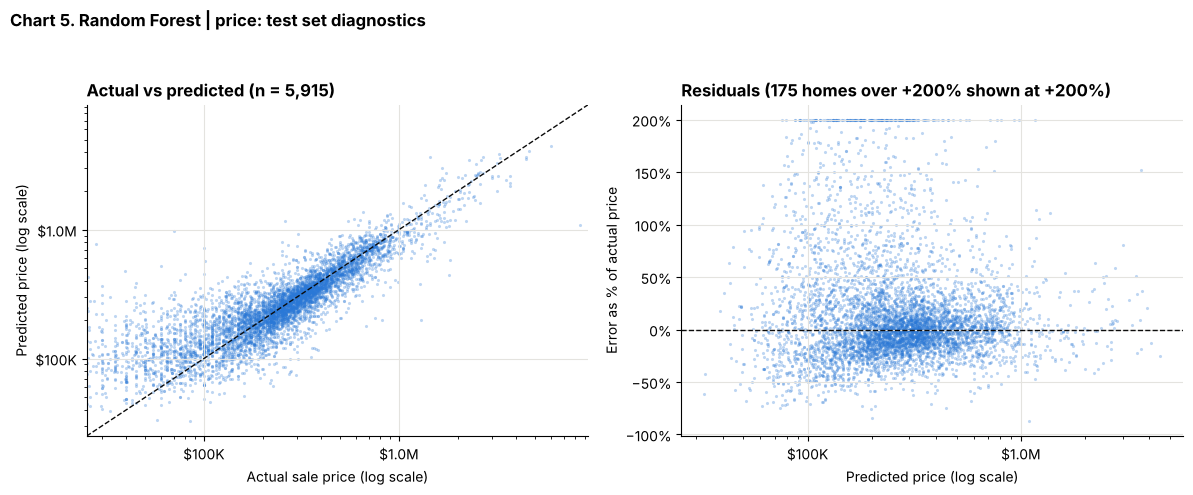

In [12]:
BLUE, INK, INK2 = "#2a78d6", "#0b0b0b", "#52514e"
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 5))
a.scatter(res["actual"], res["predicted"], s=5, alpha=0.3, color=BLUE, linewidths=0)
lims = [25_000, res[["actual", "predicted"]].max().max() * 1.1]
a.plot(lims, lims, "--", color=INK, linewidth=1)
a.set_xscale("log"); a.set_yscale("log"); a.set_xlim(lims); a.set_ylim(lims)
a.set_xlabel("Actual sale price (log scale)"); a.set_ylabel("Predicted price (log scale)")
a.set_title(f"Actual vs predicted (n = {len(res):,})", loc="left", fontweight="bold")
pct = (res["error"] / res["actual"]).clip(-1, 2)
b.scatter(res["predicted"], pct, s=5, alpha=0.3, color=BLUE, linewidths=0)
b.axhline(0, color=INK, linewidth=1, linestyle="--")
b.set_xscale("log")
b.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
b.set_xlabel("Predicted price (log scale)"); b.set_ylabel("Error as % of actual price")
b.set_title(f"Residuals ({int((pct >= 2).sum())} homes over +200% shown at +200%)", loc="left", fontweight="bold")
dollars = mtick.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M" if x >= 1e6 else f"${x/1e3:.0f}K")
a.xaxis.set_major_formatter(dollars); a.yaxis.set_major_formatter(dollars); b.xaxis.set_major_formatter(dollars)
for ax in (a, b):
    ax.grid(color="#e4e3df", linewidth=0.8); ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Chart 5. {FINAL_MODEL}: test set diagnostics", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig("figures/chart5_final_model_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

### Errors by price range (actual sale price)

In [13]:
bands = [25_000, 100_000, 200_000, 300_000, 500_000, 1_000_000, np.inf]
labels = ["$25K-100K", "$100K-200K", "$200K-300K", "$300K-500K", "$500K-1M", "$1M+"]
res["price_band"] = pd.cut(res["actual"], bands, labels=labels)
by_band = res.groupby("price_band", observed=True).agg(
    homes=("actual", "size"), MAE=("abs_error", "mean"), median_abs_pct_error=("abs_pct_error", "median"),
    mean_signed_error=("error", "mean"))
by_band.style.format({"MAE": "${:,.0f}", "median_abs_pct_error": "{:.1%}", "mean_signed_error": "${:,.0f}"})

,homes,MAE,median_abs_pct_error,mean_signed_error
price_band,,,,
$25K-100K,886,"$67,514",79.0%,"$64,752"
$100K-200K,1287,"$50,751",23.9%,"$24,590"
$200K-300K,1391,"$49,310",13.8%,"$-1,056"
$300K-500K,1414,"$62,811",11.7%,"$-11,609"
$500K-1M,751,"$118,362",13.6%,"$-33,540"
$1M+,186,"$456,475",22.9%,"$-236,648"


### Errors by ZIP (test homes; ZIPs with fewer than 30 test homes are marked)

In [14]:
res["zip_code"] = X_test["zip_code"]
by_zip = res.groupby("zip_code").agg(homes=("actual", "size"), median_actual=("actual", "median"),
                                     MAE=("abs_error", "mean"), median_abs_pct_error=("abs_pct_error", "median"),
                                     mean_signed_error=("error", "mean")).sort_values("median_abs_pct_error")
by_zip["small_sample"] = by_zip["homes"] < 30
by_zip.style.format({"median_actual": "${:,.0f}", "MAE": "${:,.0f}", "median_abs_pct_error": "{:.1%}", "mean_signed_error": "${:,.0f}"})

,homes,median_actual,MAE,median_abs_pct_error,mean_signed_error,small_sample
zip_code,,,,,,
19116,81,"$400,000","$44,364",7.3%,$828,False
19154,107,"$326,000","$42,408",8.6%,$-521,False
19115,104,"$405,000","$57,529",9.6%,"$-7,229",False
19152,97,"$320,000","$37,666",9.9%,"$-5,485",False
19123,83,"$550,000","$98,839",10.0%,"$-46,523",False
19114,125,"$315,000","$46,335",10.9%,"$2,849",False
19128,205,"$395,000","$65,942",11.0%,"$-11,464",False
19125,246,"$447,500","$74,433",11.6%,"$-20,258",False
19102,23,"$294,500","$104,434",12.2%,"$42,839",True


### Which inputs the model relies on (permutation importance, test set)
Each input is shuffled in turn; the increase in MAE shows how much the model depends on it.
This measures what the model *uses*, not what *causes* prices: correlated inputs (like area and bathrooms) share credit.

In [15]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(final, X_test, y_test, scoring="neg_mean_absolute_error",
                            n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"input": X_test.columns, "MAE increase when shuffled": pi.importances_mean,
                    "std": pi.importances_std}).sort_values("MAE increase when shuffled", ascending=False)
imp.style.format({"MAE increase when shuffled": "${:,.0f}", "std": "${:,.0f}"})

,input,MAE increase when shuffled,std
0,total_livable_area,"$67,957","$1,123"
7,zip_code,"$63,891",$987
3,year_built,"$25,693",$311
8,interior_condition,"$12,953",$485
2,number_of_bathrooms,"$11,214",$295
5,garage_spaces,"$4,505",$193
1,number_of_bedrooms,"$4,362",$137
10,central_air,"$4,218",$136
4,number_stories,"$3,729",$138
11,quality_grade,"$1,565",$221


In [16]:
with pd.ExcelWriter("figures/final_model_results.xlsx") as w:
    summary.rename("value").to_frame().to_excel(w, sheet_name="Summary")
    test_table.to_excel(w, sheet_name="All models (test)", index=False)
    cv_table.to_excel(w, sheet_name="All models (CV)", index=False)
    by_band.to_excel(w, sheet_name="By price range")
    by_zip.to_excel(w, sheet_name="By ZIP")
    imp.to_excel(w, sheet_name="Input importance", index=False)
print("saved figures/final_model_results.xlsx")

saved figures/final_model_results.xlsx


### Check: the saved file gives the same predictions as the notebook
The website must load `app/model.joblib`. This reloads it and compares predictions on 5 test homes.

In [17]:
import joblib
loaded = joblib.load("app/model.joblib")["model"]
check = X_test.head(5).copy()
check["notebook_pred"] = final.predict(X_test.head(5)).round(0)
check["saved_file_pred"] = loaded.predict(X_test.head(5)).round(0)
check["actual"] = y_test.head(5).values
print("identical:", np.allclose(check["notebook_pred"], check["saved_file_pred"]))
check[["total_livable_area", "number_of_bedrooms", "number_of_bathrooms", "zip_code", "year_built",
       "notebook_pred", "saved_file_pred", "actual"]]

identical: True


,total_livable_area,number_of_bedrooms,number_of_bathrooms,zip_code,year_built,notebook_pred,saved_file_pred,actual
35019,1200.0,3.0,1.0,19143,1925.0,203520.0,203520.0,172500.0
29644,1356.0,3.0,1.0,19145,1920.0,293385.0,293385.0,380000.0
20596,1300.0,3.0,1.0,19143,1925.0,270194.0,270194.0,257000.0
18452,984.0,3.0,1.0,19121,1915.0,89745.0,89745.0,105000.0
4011,1128.0,3.0,2.0,19128,1940.0,353793.0,353793.0,367500.0


## 11. Final website model: year and ZIP fixed effects, plus a price range
Professor feedback: add year and ZIP fixed effects. Sale year becomes a **category** (each year gets its own price level), next to ZIP
(already a category). Same data, same train/test split and same random forest settings as above, so the results are directly comparable.
This is the model the website runs: this cell saves `app/model.joblib` (replacing the one saved in section 9) and `app/price_range.json`.

In [18]:
import json
NUMERIC_FE = [c for c in NUMERIC if c != "sale_year"]
CATEGORICAL_FE = ["zip_code", "sale_year"] + [c for c in CATEGORICAL if c != "zip_code"]

def with_year_category(Xp):
    d = Xp.copy(); d["sale_year"] = d["sale_year"].astype(int).astype(str); return d

prep_fe = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median"))]), NUMERIC_FE),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CATEGORICAL_FE)])
fe_model = Pipeline([("prep", prep_fe), ("model", RandomForestRegressor(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=SEED))])
fe_model.fit(with_year_category(X_train), y_train)
p_fe = fe_model.predict(with_year_category(X_test))
compare = pd.DataFrame([{"model": FINAL_MODEL + " (sale year as a number)", **scores(y_test, CANDIDATES[FINAL_MODEL].predict(X_test))},
                        {"model": "Random Forest | price, year + ZIP fixed effects", **scores(y_test, p_fe)}])
compare.style.format({"MAE": "${:,.0f}", "RMSE": "${:,.0f}", "R2": "{:.3f}"})

,model,MAE,RMSE,R2
0,Random Forest | price (sale year as a number),"$77,149","$167,630",0.782
1,"Random Forest | price, year + ZIP fixed effects","$77,211","$167,737",0.782


### 80% price range
For each band of estimated price, the range runs from the 10th to the 90th percentile of (actual / predicted) on the test homes.
To check it honestly, the multipliers are first set on a random half of the test homes and checked on the other half; the saved table then uses all test homes.

In [19]:
ratio = y_test.values / p_fe
BANDS = [0, 100_000, 200_000, 300_000, 500_000, 1_000_000, np.inf]
band = np.digitize(p_fe, BANDS[1:-1])
half = np.random.default_rng(SEED).random(len(ratio)) < 0.5
rows, inside_all = [], []
for b in range(len(BANDS) - 1):
    m = band == b
    lo_c, hi_c = np.quantile(ratio[m & half], [0.10, 0.90])
    inside = (ratio[m & ~half] >= lo_c) & (ratio[m & ~half] <= hi_c); inside_all.append(inside)
    lo, hi = np.quantile(ratio[m], [0.10, 0.90])
    rows.append({"band_low": BANDS[b], "band_high": None if np.isinf(BANDS[b + 1]) else BANDS[b + 1], "test_homes": int(m.sum()),
                 "low_mult": round(float(lo), 3), "high_mult": round(float(hi), 3), "holdout_coverage": round(float(inside.mean()), 3)})
print("held-out coverage of the 80% range:", round(float(np.concatenate(inside_all).mean()), 3))
pd.DataFrame(rows)

held-out coverage of the 80% range: 0.778


,band_low,band_high,test_homes,low_mult,high_mult,holdout_coverage
0,0,100000.0,478,0.483,1.864,0.799
1,100000,200000.0,1529,0.437,1.519,0.780
2,200000,300000.0,1519,0.564,1.310,0.794
3,300000,500000.0,1484,0.692,1.273,0.769
4,500000,1000000.0,746,0.698,1.316,0.748
5,1000000,NaN,159,0.666,1.444,0.754


In [ ]:
import joblib
os.makedirs("app", exist_ok=True)
joblib.dump({"model": fe_model, "numeric": NUMERIC_FE, "categorical": CATEGORICAL_FE,
             "trained_on": "philly_sf_sales_clean.csv, bundles dropped, random 80/20 train split, seed 42"},
            "app/model.joblib", compress=3)
json.dump({"level": 0.8, "method": "10th and 90th percentile of actual/predicted on the test homes, by predicted price band", "bands": rows},
          open("app/price_range.json", "w"), indent=2)

case = pd.DataFrame([{"total_livable_area": 1200.0, "number_of_bedrooms": 3.0, "number_of_bathrooms": 1.0, "year_built": 1925.0,
                      "number_stories": 1.0, "garage_spaces": np.nan, "sale_year": "2026", "zip_code": "19143",
                      "interior_condition": "2", "exterior_condition": "4", "central_air": np.nan, "quality_grade": "C"}])
case[CATEGORICAL_FE] = case[CATEGORICAL_FE].astype(object)
pc = joblib.load("app/model.joblib")["model"].predict(case)[0]
r = next(b for b in rows if b["band_high"] is None or pc < b["band_high"])
print(f"saved app/model.joblib and app/price_range.json | scikit-learn {sklearn.__version__}")
print(f"test case: ${pc:,.0f} | likely range ${pc * r['low_mult']:,.0f} to ${pc * r['high_mult']:,.0f}")

saved app/model.joblib and app/price_range.json | scikit-learn 1.9.1
test case: $202,077 | likely range $113,972 to $264,721
